<a href="https://colab.research.google.com/github/Lienle189/Machine_Learning/blob/main/LeThiLien_ML_Buoi1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Buổi 1. Hồi quy (Regression)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             confusion_matrix, classification_report,
                             precision_score, recall_score)


## III. Bài tập ở lớp
### Bài 1. Dự đoán giá nhà theo diện tích
###Bài 1. Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).
1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên
Diện tích nhà.
2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.
#### Câu 1. Hồi quy tuyến tính đơn giản

Intercept: 562.9334459187971
Slope    : 29.965620356487836
MSE      : 82597.79222742857
R2       : 0.9420440502725198


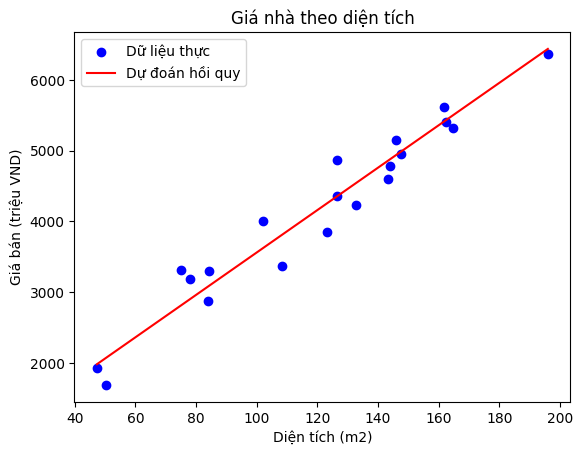

In [ ]:
np.random.seed(0)
n = 100
dien_tich = np.random.uniform(30, 200, n)                 # m2
gia = 500 + 30 * dien_tich + np.random.randn(n) * 300     # triệu VND (có nhiễu)

df = pd.DataFrame({"DienTich": dien_tich, "Gia": gia})
X = df[["DienTich"]]
y = df["Gia"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Intercept:", model.intercept_)
print("Slope    :", model.coef_[0])
print("MSE      :", mean_squared_error(y_test, y_pred))
print("R2       :", r2_score(y_test, y_pred))

plt.scatter(X_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(X_test.sort_values("DienTich"), model.predict(X_test.sort_values("DienTich")),
         color="red", label="Dự đoán hồi quy")
plt.xlabel("Diện tích (m2)"); plt.ylabel("Giá bán (triệu VND)")
plt.title("Giá nhà theo diện tích"); plt.legend(); plt.show()


#### Câu 2. Tăng số lượng dữ liệu và độ nhiễu

In [ ]:
def chay_bai1(n, noise, seed=0):
    rng = np.random.RandomState(seed)
    dt = rng.uniform(30, 200, n)
    g = 500 + 30 * dt + rng.randn(n) * noise
    Xa = dt.reshape(-1, 1)
    Xtr, Xte, ytr, yte = train_test_split(Xa, g, test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    yp = m.predict(Xte)
    return mean_squared_error(yte, yp), r2_score(yte, yp), m.coef_[0]

rows = []
for n in [50, 200, 1000]:
    for noise in [100, 300, 800]:
        mse, r2, slope = chay_bai1(n, noise)
        rows.append({"n": n, "noise": noise, "slope": round(slope, 2),
                     "MSE": round(mse, 1), "R2": round(r2, 3)})
pd.DataFrame(rows)


,n,noise,slope,MSE,R2
0,50,100,29.72,5564.9,0.997
1,50,300,29.16,50083.9,0.972
2,50,800,27.76,356152.4,0.830
3,200,100,29.76,7344.9,0.996
4,200,300,29.27,66104.1,0.966
5,200,800,28.05,470073.8,0.765
6,1000,100,29.90,7779.0,0.996
7,1000,300,29.69,70010.8,0.968
8,1000,800,29.18,497854.7,0.815


#### Câu 3. Thêm các biến đầu vào (số phòng ngủ, khoảng cách đến trung tâm)

In [ ]:
np.random.seed(0)
n = 300
dien_tich = np.random.uniform(30, 200, n)
phong_ngu = np.random.randint(1, 6, n)
khoang_cach = np.random.uniform(1, 20, n)
gia = 500 + 30*dien_tich + 150*phong_ngu - 40*khoang_cach + np.random.randn(n)*300

df2 = pd.DataFrame({"DienTich": dien_tich, "PhongNgu": phong_ngu,
                    "KhoangCach": khoang_cach, "Gia": gia})

def danh_gia(cols):
    Xtr, Xte, ytr, yte = train_test_split(df2[cols], df2["Gia"], test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    yp = m.predict(Xte)
    return m, mean_squared_error(yte, yp), r2_score(yte, yp)

m1, mse1, r2_1 = danh_gia(["DienTich"])
m3, mse3, r2_3 = danh_gia(["DienTich", "PhongNgu", "KhoangCach"])
print(f"1 biến : MSE={mse1:.1f}  R2={r2_1:.3f}")
print(f"3 biến : MSE={mse3:.1f}  R2={r2_3:.3f}")
print("Hệ số 3 biến:", dict(zip(["DienTich", "PhongNgu", "KhoangCach"], m3.coef_.round(2))),
      "| Intercept:", round(m3.intercept_, 2))


1 biến : MSE=135285.4  R2=0.942
3 biến : MSE=72563.4  R2=0.969
Hệ số 3 biến: {'DienTich': np.float64(29.79), 'PhongNgu': np.float64(173.85), 'KhoangCach': np.float64(-44.31)} | Intercept: 481.42


### Bài 2. Dự đoán khả năng mắc bệnh theo BMI (Logistic Regression)
Giả sử có một tập dữ liệu với các thông tin sau:
- BMI: Chỉ số khối cơ thể của bệnh nhân (Body Mass Index).
- Mắc bệnh: Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
Yêu cầu:
1. - Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic
(BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
2. - Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.
3. - Huấn luyện mô hình trên tập dữ liệu mẫu.
4. - Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra.
5. - Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn.
6. - Trực quan hóa dữ liệu và đường hồi quy logistic.



MacBenh
1    211
0    189
Name: count, dtype: int64
Hệ số: 0.44085476158851405 | Intercept: -11.882769189172782
    BMI  P(mắc bệnh)  Dự đoán  Thực tế
0  37.4        0.990        1        1
1  22.3        0.115        0        0
2  29.2        0.730        1        1
3  39.8        0.996        1        1
4  32.9        0.932        1        1
5  29.2        0.726        1        1
6  24.5        0.253        0        0
7  22.2        0.111        0        0
Accuracy: 0.9125
Confusion matrix:
 [[36  1]
 [ 6 37]]
              precision    recall  f1-score   support

           0       0.86      0.97      0.91        37
           1       0.97      0.86      0.91        43

    accuracy                           0.91        80
   macro avg       0.92      0.92      0.91        80
weighted avg       0.92      0.91      0.91        80



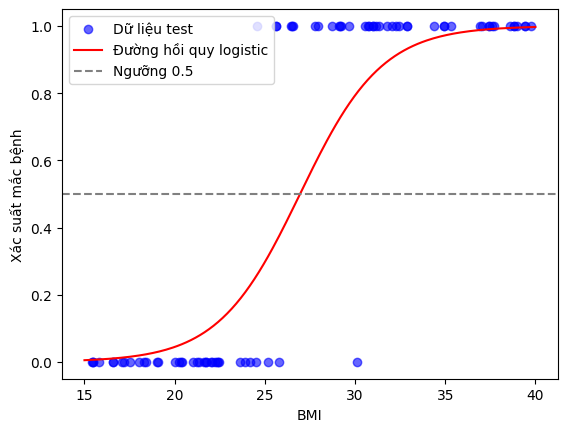

In [ ]:
# 1. Tạo dữ liệu giả lập: BMI càng cao thì xác suất mắc bệnh càng lớn
np.random.seed(0)
n = 400
bmi = np.random.uniform(15, 40, n)
p_that = 1 / (1 + np.exp(-0.5 * (bmi - 27)))
mac_benh = (np.random.rand(n) < p_that).astype(int)
data = pd.DataFrame({"BMI": bmi, "MacBenh": mac_benh})
print(data["MacBenh"].value_counts())

# 2-3. Chia dữ liệu, tạo và huấn luyện mô hình
X = data[["BMI"]]
y = data["MacBenh"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = LogisticRegression().fit(X_train, y_train)
print("Hệ số:", clf.coef_[0][0], "| Intercept:", clf.intercept_[0])

# 4. Dự đoán xác suất và nhãn
proba = clf.predict_proba(X_test)[:, 1]
y_pred = clf.predict(X_test)
print(pd.DataFrame({"BMI": X_test["BMI"].values[:8].round(1),
                    "P(mắc bệnh)": proba[:8].round(3),
                    "Dự đoán": y_pred[:8],
                    "Thực tế": y_test.values[:8]}))

# 5. Đánh giá
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# 6. Trực quan hóa
xs = np.linspace(15, 40, 200).reshape(-1, 1)
plt.scatter(X_test, y_test, color="blue", alpha=0.6, label="Dữ liệu test")
plt.plot(xs, clf.predict_proba(pd.DataFrame(xs, columns=["BMI"]))[:, 1], color="red", label="Đường hồi quy logistic")
plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng 0.5")
plt.xlabel("BMI"); plt.ylabel("Xác suất mắc bệnh"); plt.legend(); plt.show()


### Bài 3. Tự chọn bộ dữ liệu
Dùng bộ **Diabetes** có sẵn trong scikit-learn (442 bệnh nhân, 10 đặc trưng, mục tiêu là mức độ tiến triển bệnh sau 1 năm). Nếu dùng dữ liệu Kaggle thì thay dòng tải dữ liệu bằng `df = pd.read_csv('ten_file.csv')` và giữ nguyên các bước sau.

In [ ]:
from sklearn.datasets import load_diabetes
d = load_diabetes(as_frame=True)
df3 = d.frame            # cột 'target' là biến cần dự đoán

# Bước 1: đánh giá thực trạng dữ liệu
print(df3.shape)
print(df3.head())
df3.info()
print(df3.describe().T)
print("Giá trị thiếu:\n", df3.isnull().sum())
print("Số dòng trùng:", df3.duplicated().sum())


(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float

target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


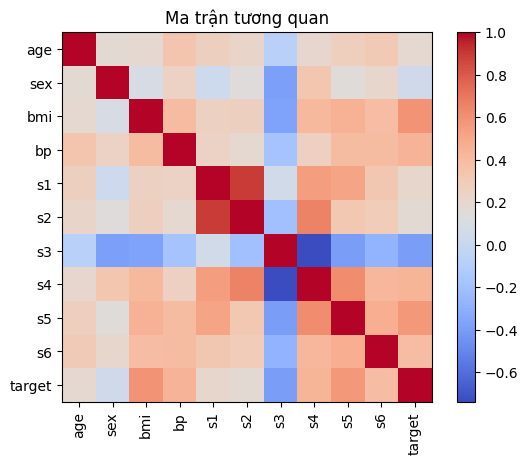

In [ ]:
# Bước 2: tương quan giữa các biến
corr = df3.corr()
print(corr["target"].sort_values(ascending=False))
plt.imshow(corr, cmap="coolwarm"); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
plt.title("Ma trận tương quan"); plt.show()


MSE: 2900.1936284934804
RMSE: 53.85344583676592
R2 : 0.4526027629719197
s1    -44.448856
sex   -11.511809
age     1.753758
s6      2.351364
s3      7.676978
s4     13.138784
bp     16.828872
s2     24.640954
bmi    25.607121
s5     35.161195
dtype: float64


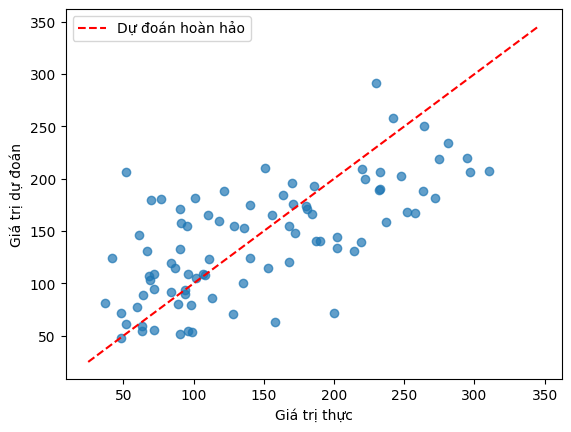

In [ ]:
# Bước 3: tiền xử lý (không có giá trị thiếu; chuẩn hóa đặc trưng) và chia dữ liệu
X = df3.drop(columns="target")
y = df3["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train)       # chỉ fit trên tập train để tránh rò rỉ dữ liệu
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Bước 4: huấn luyện, dự đoán, đánh giá
model = LinearRegression().fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 :", r2_score(y_test, y_pred))
print(pd.Series(model.coef_, index=X.columns).sort_values())

# Bước 5: biểu đồ thực tế vs dự đoán
plt.scatter(y_test, y_pred, alpha=0.7)
lim = [y.min(), y.max()]
plt.plot(lim, lim, "r--", label="Dự đoán hoàn hảo")
plt.xlabel("Giá trị thực"); plt.ylabel("Giá trị dự đoán"); plt.legend(); plt.show()


## IV. Bài tập về nhà
### Bài 1. Thay đổi điều kiện sinh dữ liệu (tăng nhiễu)

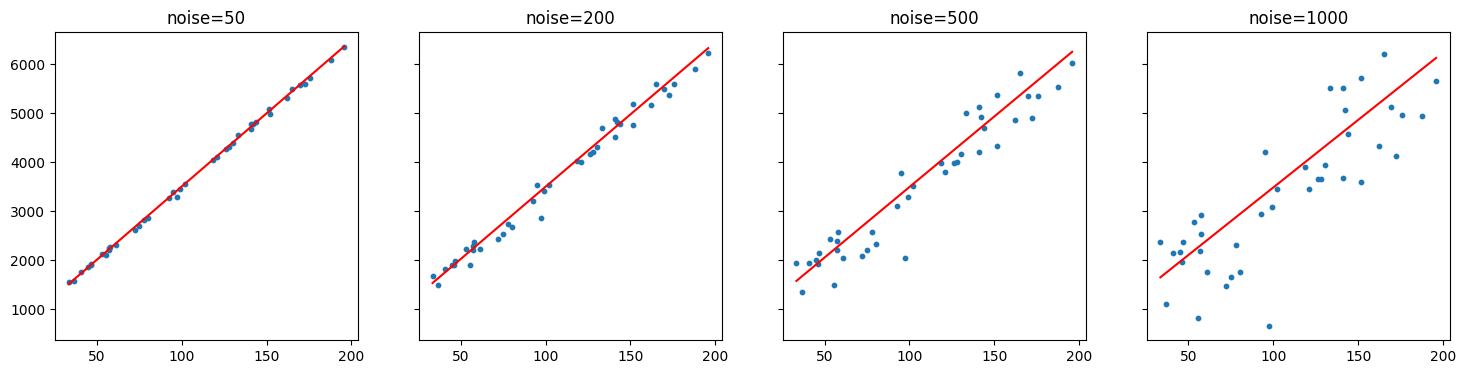

,noise,slope,MSE,R2
0,50,29.88,1836.2,0.999
1,200,29.51,29379.6,0.985
2,500,28.78,183622.6,0.904
3,1000,27.56,734490.2,0.655


In [ ]:
res = []
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, noise in zip(axes, [50, 200, 500, 1000]):
    rng = np.random.RandomState(0)
    xs_ = rng.uniform(30, 200, 200)
    ys_ = 500 + 30 * xs_ + rng.randn(200) * noise
    Xa = xs_.reshape(-1, 1)
    Xtr, Xte, ytr, yte = train_test_split(Xa, ys_, test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    yp = m.predict(Xte)
    res.append({"noise": noise, "slope": round(m.coef_[0], 2),
                "MSE": round(mean_squared_error(yte, yp), 1), "R2": round(r2_score(yte, yp), 3)})
    ax.scatter(Xte, yte, s=10); ax.plot(np.sort(Xte, axis=0), m.predict(np.sort(Xte, axis=0)), "r")
    ax.set_title(f"noise={noise}")
plt.show()
pd.DataFrame(res)


### Bài 2. Đổi ngưỡng dự đoán xác suất (dùng mô hình Bài 2 ở lớp)

In [ ]:
# Tạo lại tập test của Bài 2 ở lớp (cùng random_state nên giống hệt) để không bị ghi đè bởi các bài khác
Xb, yb = data[["BMI"]], data["MacBenh"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, random_state=42)
clf_b = LogisticRegression().fit(Xb_train, yb_train)
proba_b = clf_b.predict_proba(Xb_test)[:, 1]

rows = []
for t in [0.3, 0.5, 0.6, 0.7, 0.8]:
    yp = (proba_b >= t).astype(int)
    rows.append({"Ngưỡng": t,
                 "Accuracy": round(accuracy_score(yb_test, yp), 3),
                 "Precision": round(precision_score(yb_test, yp, zero_division=0), 3),
                 "Recall": round(recall_score(yb_test, yp), 3),
                 "Số dự đoán 'mắc bệnh'": int(yp.sum())})
    print(f"Ngưỡng {t}:\n{confusion_matrix(yb_test, yp)}")
pd.DataFrame(rows)


Ngưỡng 0.3:
[[34  3]
 [ 1 42]]
Ngưỡng 0.5:
[[36  1]
 [ 6 37]]
Ngưỡng 0.6:
[[36  1]
 [ 7 36]]
Ngưỡng 0.7:
[[36  1]
 [ 9 34]]
Ngưỡng 0.8:
[[36  1]
 [13 30]]


,Ngưỡng,Accuracy,Precision,Recall,Số dự đoán 'mắc bệnh'
0,0.3,0.950,0.933,0.977,45
1,0.5,0.912,0.974,0.860,38
2,0.6,0.900,0.973,0.837,37
3,0.7,0.875,0.971,0.791,35
4,0.8,0.825,0.968,0.698,31


### Bài 3. Hồi quy tuyến tính với dữ liệu giá nhà
`load_boston` đã bị xóa khỏi scikit-learn (từ bản 1.2) nên dùng **California Housing** (thay thế chính thức). Dữ liệu sẽ được tải tự động khi chạy trên Colab.

(20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
0 giá trị thiếu
MSE: 0.5558915986952444
R2 : 0.5757877060324508
MedInc        0.4487
HouseAge      0.0097
AveRooms     -0.1233
AveBedrms     0.7831
Population   -0.0000
AveOccup     -0.0035
Latitude     -0.4198
Longitude    -0.4337
dtype: float64


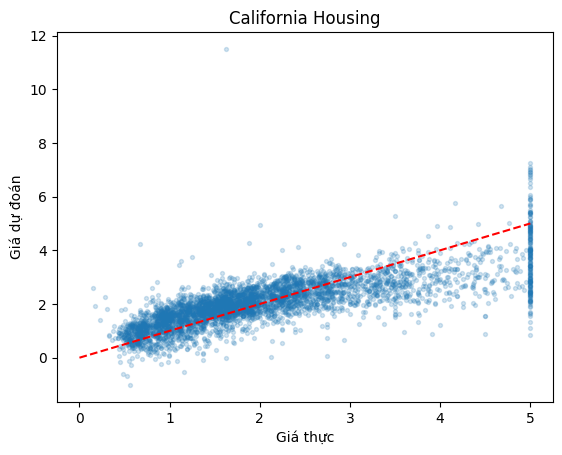

In [ ]:
from sklearn.datasets import fetch_california_housing
cal = fetch_california_housing(as_frame=True)
dfh = cal.frame          # cột 'MedHouseVal' là giá nhà (đơn vị 100.000 USD)
print(dfh.shape); print(dfh.head()); print(dfh.isnull().sum().sum(), "giá trị thiếu")

X = dfh.drop(columns="MedHouseVal")
y = dfh["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 :", r2_score(y_test, y_pred))
print(pd.Series(model.coef_, index=X.columns).round(4))

plt.scatter(y_test, y_pred, alpha=0.2, s=8)
plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Giá thực"); plt.ylabel("Giá dự đoán"); plt.title("California Housing"); plt.show()
